# Clustering: KMeans

## Setup

### Load

In [140]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

### Util

In [141]:
behavior_cols = [
    'average_score_full',
    'bonus_score_episode_ratio',
    'road_crossing_success_ratio_total',
    'sideway_movements_in_crosswalk_not_visible_safe_zone_cnt_high_to_low_penalty',
    'run_over_episode_ratio',
]

irl_cols = [
    "safest_road_crossing_irl",
    "move_up_toward_car_irl",
    "waiting_for_car_to_pass_irl",
    "high_risk_but_empty_last_road_irl",
    "approaching_crosswalk_in_current_road_irl",
    "approaching_next_crosswalks_irl",
]
feature_cols = behavior_cols + irl_cols

target_cols = [
  "DOSPERT",
  "DOSPERT_ETH",
  "DOSPERT_FIN",
  "DOSPERT_HEA",
  "DOSPERT_REC",
  "DOSPERT_SOC",
]

rename_dict = {
  "total_score_full": "Total Score",
  "average_score_full": "Average Score",
  "bonus_score_episode_ratio": "Episode Clear Ratio",
  "road_crossing_success_ratio_total": "Road Crossing\nSuccess Ratio",
  "run_over_episode_ratio": "Run Over Ratio",
  "sideway_movements_in_crosswalk_not_visible_safe_zone_cnt_high_to_low_penalty": "Crosswalk Searching",

  "safest_road_crossing_irl": "[IRL] Safest Road Crossing",
  "move_up_toward_car_irl": "[IRL] Moving Up Toward Car",
  "waiting_for_car_to_pass_irl": "[IRL] Waiting in Crosswalk\nfor Car to Pass",
  "outside_of_crosswalk_irl": "[IRL] Outside of crosswalk",
  "high_risk_but_empty_last_road_irl": "[IRL] High Risk but\nEmpty Last Road",
  "approaching_crosswalk_in_current_road_irl": "[IRL] Approaching Crosswalk\nin Current Road",
  "approaching_next_crosswalks_irl": "[IRL] Approaching\nNext Crosswalks",
  
  "DOSPERT": "DOSPERT",
  "DOSPERT_ETH": "DOSPERT (Ethical)",
  "DOSPERT_FIN": "DOSPERT (Financial)",
  "DOSPERT_HEA": "DOSPERT (Health Safety)",
  "DOSPERT_REC": "DOSPERT (Recreational)",
  "DOSPERT_SOC": "DOSPERT (Social)",
}

risk_taking_aversion_dict = {
  "total_score_full": "Risk Aversion",
  "average_score_full": "Risk Aversion",
  "bonus_score_episode_ratio": "Risk Aversion",
  "road_crossing_success_ratio_total": "Risk Aversion",
  "run_over_episode_ratio": "Risk Taking",
  "sideway_movements_in_crosswalk_not_visible_safe_zone_cnt_high_to_low_penalty": "Risk Aversion",

  "safest_road_crossing_irl": "Risk Aversion",
  "move_up_toward_car_irl": "Risk Taking",
  "waiting_for_car_to_pass_irl": "Risk Aversion",
  "outside_of_crosswalk_irl": "Risk Taking",
  "high_risk_but_empty_last_road_irl": "Risk Taking",
  "approaching_crosswalk_in_current_road_irl": "Risk Taking",
  "approaching_next_crosswalks_irl": "Risk Taking",
}

cols = feature_cols + target_cols

In [142]:
def p_to_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""

In [143]:
def cohens_d(x, y):
    nx = len(x)
    ny = len(y)
    pooled_sd = np.sqrt(((nx-1)*np.var(x, ddof=1) + (ny-1)*np.var(y, ddof=1)) / (nx + ny - 2))
    return (np.mean(x) - np.mean(y)) / pooled_sd

## Data

In [144]:
df = pd.read_csv("data/data_integrated_irl.csv")
print(f"N={len(df)}")
df.head()

N=282


,subj_id,age,gender,BIS,BIS_motor,BIS_nonplanning,BIS_attentional,BIS_same_response,STAI,STAI_S,...,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_high_penalty_session2,DDT_mean_log_k,CRA_mean_alpha,web,safest_road_crossing_irl,waiting_for_car_to_pass_irl,high_risk_but_empty_last_road_irl,approaching_crosswalk_in_current_road_irl,approaching_next_crosswalks_irl,move_up_toward_car_irl
0,904,22,1,73,23,31,19,-1,87,44,...,14,-3.272599,0.347513,False,0.748267,-0.258253,-0.128665,0.608656,0.356492,0.579928
1,1000,32,2,61,18,22,21,-1,84,38,...,7,-6.330838,0.660547,False,0.492620,-0.838224,-0.060370,0.450264,0.492121,0.753004
2,1001,25,2,73,20,31,22,-1,77,38,...,6,-7.961866,0.612792,False,0.663715,0.122388,-1.073019,0.427394,0.443287,0.089030
3,1002,21,2,63,22,22,19,-1,73,38,...,4,-1.564452,1.412119,False,0.223814,-0.900335,0.055749,0.549780,0.407102,0.497768
4,1003,26,2,69,22,24,23,-1,86,40,...,17,-5.378190,0.668441,False,0.464243,-0.561648,0.423064,0.572266,0.436846,0.555052


In [145]:
df_clustering = df[feature_cols + ["DOSPERT"]].copy()
X = StandardScaler().fit_transform(df_clustering[feature_cols])

## Selecting the number of clusters

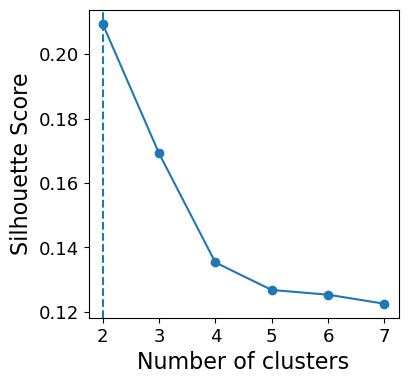

Best k: 2
Best silhouette: 0.20943474436841483


In [146]:
from sklearn.metrics import silhouette_score

Ks = range(2, 7+1)

scores = []

for k in Ks:
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=100
    )

    labels = km.fit_predict(X)

    score = silhouette_score(X, labels)
    scores.append(score)

best_k = Ks[np.argmax(scores)]

plt.figure(figsize=(4,4))
plt.plot(Ks, scores, marker='o')

# plt.title(f"KMeans: Best k = {best_k}", fontsize=16)
# plt.xlabel("Number of clusters (k)", fontsize=14)
plt.xlabel("Number of clusters", fontsize=16)
plt.ylabel("Silhouette Score", fontsize=16)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
plt.axvline(x=best_k, linestyle='--')

plt.show()

print("Best k:", best_k)
print("Best silhouette:", max(scores))

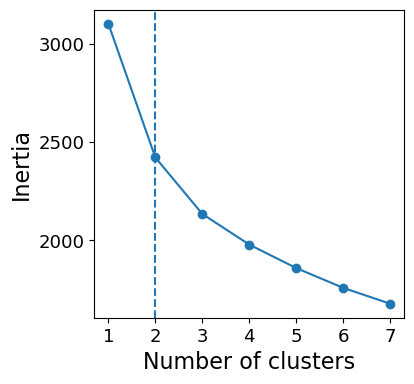

In [147]:
Ks = range(1, 7+1)
inertias = []

for k in Ks:
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=100
    )
    km.fit(X)
    inertias.append(km.inertia_)

plt.figure(figsize=(4,4))

# plt.title("KMeans: Elbow plot", fontsize=16)
plt.plot(Ks, inertias, marker='o')
plt.xlabel("Number of clusters", fontsize=16)
plt.ylabel("Inertia", fontsize=16) # Within-cluster sum of squares
plt.xticks(fontsize=13)
plt.yticks(ticks=[2000, 2500, 3000], fontsize=13)

plt.axvline(x=2, linestyle='--')
plt.show()

## Generate clusters

In [148]:
np.random.seed(42)
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10, # [centroid 랜덤 초기화 => KMeans 수행 => inertia(군집 내 거리합) 계산] 과정을 10번 반복
)
labels = kmeans.fit_predict(X)

## DOSPERT difference between Clusters

,count,mean,std,min,max
cluster,,,,,
0,117,33.161783,13.437478,0.571429,71.428571
1,165,26.743146,12.044745,1.714286,64.571429


Cluster 0: N=117, Mean=33.162, SD=13.437
Cluster 1: N=165, Mean=26.743, SD=12.045
Welch's t(232.5) = -4.12, p = 0.0001, d = 0.51


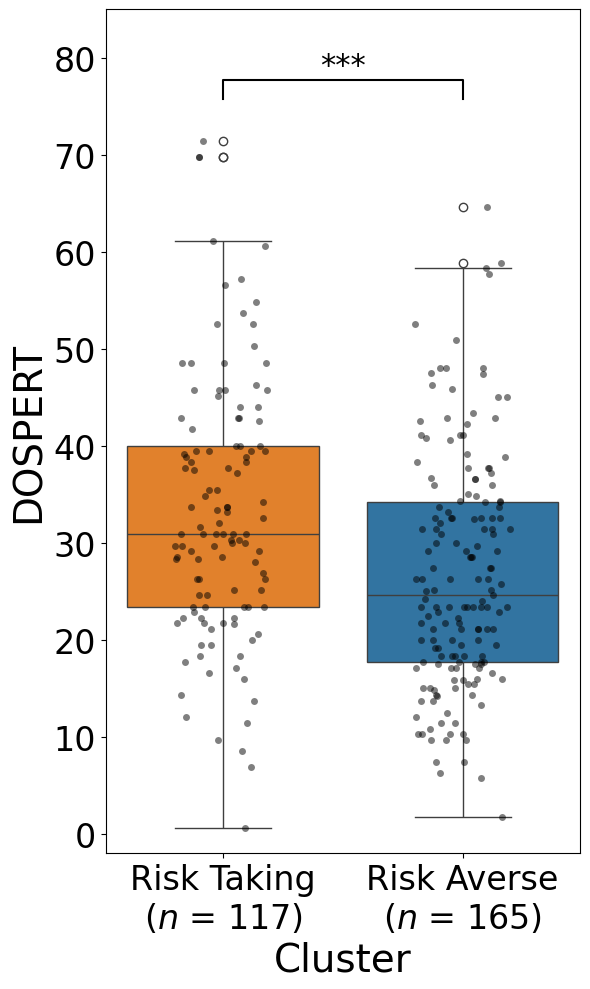

In [ ]:
fig, ax = plt.subplots(figsize=(6, 10))

df_clustering["cluster"] = labels

# Cluster summary
summary = df_clustering.groupby("cluster")["DOSPERT"].agg(["count", "mean", "std", "min", "max"])
display(summary)

# t-test + effect size
group0 = df_clustering.loc[df_clustering["cluster"] == 0, "DOSPERT"]
group1 = df_clustering.loc[df_clustering["cluster"] == 1, "DOSPERT"]

# Welch's t-test
result = ttest_ind(group1, group0, equal_var=False)
t = result.statistic
p = result.pvalue
degree_of_freedom = result.df

d = cohens_d(group0, group1) # Cohen's d

print(f"Cluster 0: N={len(group0)}, Mean={group0.mean():.3f}, SD={group0.std():.3f}")
print(f"Cluster 1: N={len(group1)}, Mean={group1.mean():.3f}, SD={group1.std():.3f}")
print(
    f"Welch's t({degree_of_freedom:.1f}) = {t:.2f}, "
    f"p = {p:.4f}, "
    f"d = {d:.2f}"
)

cluster_order = [0, 1]
cluster_palette = {
    0: "#ff7f0e", # orange
    1: "#1f77b4", # blue
}
cluster_labels = [
    f"Risk Taking\n($n$ = {len(group0)})",
    f"Risk Averse\n($n$ = {len(group1)})",
]

sns.boxplot(
    data=df_clustering,
    x="cluster",
    y="DOSPERT",
    order=cluster_order,
    hue="cluster",
    palette=cluster_palette,
    legend=False,
    ax=ax,
)
sns.stripplot(
    data=df_clustering,
    x="cluster",
    y="DOSPERT",
    order=cluster_order,
    color="black",
    alpha=0.5,
    jitter=0.2,
    ax=ax,
)

def add_significance_bar(
    ax,
    x1,
    x2,
    y,
    height,
    text,
    fontsize=16,
    linewidth=1.5,
):
    # └────┘
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + height, y + height, y],
        color="black",
        linewidth=linewidth,
        clip_on=False,
    )

    ax.text(
        (x1 + x2) / 2,
        y + height,
        text,
        ha="center",
        va="bottom",
        fontsize=fontsize,
    )

y_bottom, y_top = ax.get_ylim()
y_range = y_top - y_bottom

bar_y = y_top + 0.01 * y_range
bar_height = 0.025 * y_range

add_significance_bar(
    ax=ax,
    x1=0,
    x2=1,
    y=bar_y,
    height=bar_height,
    text=p_to_star(p),
    fontsize=22,
)

# ax.set_ylim(y_bottom, bar_y + bar_height + 0.10 * y_range)
ax.set_ylim(-2, 85)

ax.set_xlabel("Cluster", fontsize=28)
ax.set_ylabel("DOSPERT", fontsize=28)

ax.set_xticks([0, 1])
ax.set_xticklabels(cluster_labels, fontsize=24)
ax.tick_params(axis="y", labelsize=24)

plt.tight_layout()
plt.show()

## Difference in risk preference indicators between Clusters

,feature,mean_0,mean_1,mean_diff,t,p,cohens_d,significance,indicator,feature_description
0,average_score_full,703.140500,1000.897686,297.757186,-21.062534,5.623449e-57,-2.557215,***,Risk Aversion,Average Score
2,road_crossing_success_ratio_total,0.909579,0.943436,0.033857,-18.981594,2.922764e-47,-2.397402,***,Risk Aversion,Road Crossing\nSuccess Ratio
1,bonus_score_episode_ratio,0.433254,0.606529,0.173275,-16.051145,8.538638e-39,-2.005869,***,Risk Aversion,Episode Clear Ratio
4,run_over_episode_ratio,0.503252,0.367409,-0.135843,15.611406,2.021222e-37,1.949371,***,Risk Taking,Run Over Ratio
6,move_up_toward_car_irl,0.465518,0.322434,-0.143084,5.342058,2.035700e-07,0.641818,***,Risk Taking,[IRL] Moving Up Toward Car
5,safest_road_crossing_irl,0.350560,0.537371,0.186811,-5.325447,2.850219e-07,-0.686757,***,Risk Aversion,[IRL] Safest Road Crossing
3,sideway_movements_in_crosswalk_not_visible_saf...,0.043325,0.120985,0.077661,-2.280576,2.373127e-02,-0.296143,*,Risk Aversion,Crosswalk Searching
10,approaching_next_crosswalks_irl,0.420672,0.375204,-0.045468,1.736163,8.370648e-02,0.206568,,Risk Taking,[IRL] Approaching\nNext Crosswalks
7,waiting_for_car_to_pass_irl,-0.369108,-0.269066,0.100042,-1.665783,9.717036e-02,-0.207431,,Risk Aversion,[IRL] Waiting in Crosswalk\nfor Car to Pass
8,high_risk_but_empty_last_road_irl,-0.200254,-0.209994,-0.009741,0.305689,7.601252e-01,0.037967,,Risk Taking,[IRL] High Risk but\nEmpty Last Road


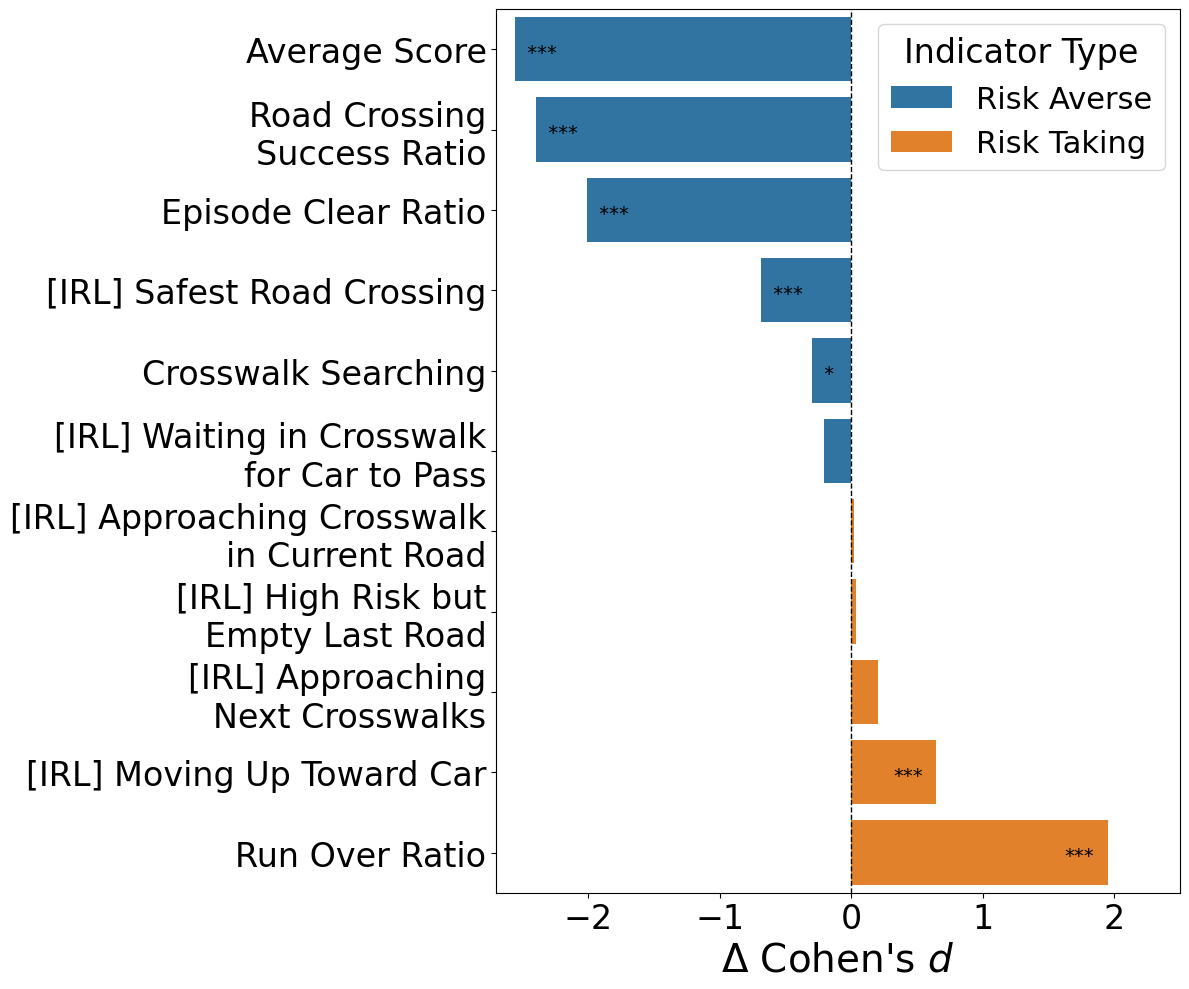

In [178]:
results = []

for col in feature_cols:
    group1 = df_clustering.loc[df_clustering["cluster"] == 1, col].dropna()
    group0 = df_clustering.loc[df_clustering["cluster"] == 0, col].dropna()

    t, p = ttest_ind(group0, group1, equal_var=False)

    d = cohens_d(group0, group1)

    results.append({
        "feature": col,
        "mean_0": group0.mean(),
        "mean_1": group1.mean(),
        "mean_diff": group1.mean() - group0.mean(),
        "t": t,
        "p": p,
        "cohens_d": d,
        "significance": p_to_star(p),
        "indicator": risk_taking_aversion_dict[col],
    })

result_df = pd.DataFrame(results)
result_df["feature_description"] = result_df["feature"].map(
    lambda col: f"{rename_dict[col]}"
)
display(result_df.sort_values("p"))

########

plot_df = result_df.copy()
plot_df = plot_df.sort_values("cohens_d")

plot_df["Indicator Type"] = np.where(
    plot_df["cohens_d"] >= 0,
    "Risk Taking",
    "Risk Averse",
)

palette = {
    "Risk Taking": "#ff7f0e", # orange
    "Risk Averse": "#1f77b4", # blue
}

plt.figure(figsize=(12, 10))

ax = sns.barplot(data=plot_df, x="cohens_d", y="feature_description", orient="h",
                 order=plot_df["feature_description"], hue="Indicator Type", palette=palette)

plt.axvline(0, linestyle="--", linewidth=1, color="black")

star_x_offset = 0.1
star_y_offset = 0.04
for i, row in enumerate(plot_df.itertuples()):
    if row.cohens_d > 0:
        ax.text(row.cohens_d - star_x_offset, i + star_y_offset, row.significance, ha="right", va="center", fontsize=14)
    else:
        ax.text(row.cohens_d, i + star_y_offset, f"  {row.significance}", ha="left", va="center", fontsize=14)


# plt.xlabel("Difference in Cohen's d", fontsize=14)
plt.xlabel(r"$\Delta$ Cohen's $d$", fontsize=28)
plt.xticks([-2, -1, 0, 1, 2], fontsize=24)
plt.xlim(-2.7, 2.5)
plt.yticks(fontsize=24)
plt.ylabel("")
ax.legend(title="Indicator Type", title_fontsize=24, fontsize=22, loc="upper right")

ax.margins(x=0.03)

plt.tight_layout()
plt.show()

## 3D Scatter plot

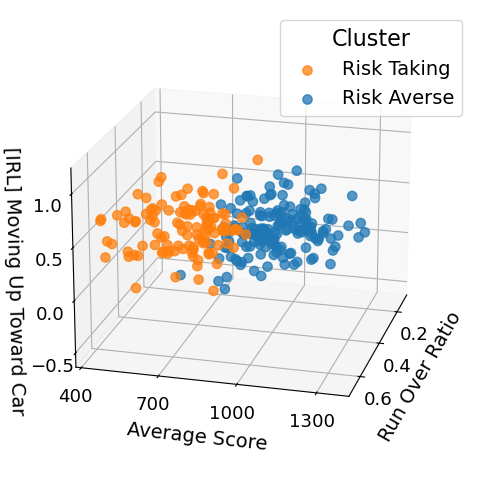

In [210]:
import matplotlib.pyplot as plt

features = [
    "run_over_episode_ratio",
    "average_score_full", 
    "move_up_toward_car_irl",
]
# features = [
#     "average_score_full", 
#     "run_over_episode_ratio",
#     "safest_road_crossing_irl",
# ]

fig = plt.figure(figsize=(8, 6)) #, constrained_layout=True)
ax = fig.add_subplot(111, projection="3d")

for cluster_name, group in df_clustering.groupby("cluster"):
    ax.scatter(
        group[features[0]],
        group[features[1]],
        group[features[2]],
        label=f"Risk Taking" if cluster_name == 0 else f"Risk Averse",
        color=cluster_palette[cluster_name],
        s=45,
        alpha=0.75,
    )

ax.xaxis.set_rotate_label(True)
ax.yaxis.set_rotate_label(True)
ax.zaxis.set_rotate_label(True)

ax.set_xlabel(rename_dict[features[0]], labelpad=6, fontsize=14) #, labelpad=10)
ax.set_ylabel(rename_dict[features[1]], labelpad=10, fontsize=14) #, labelpad=10)
ax.set_zlabel(rename_dict[features[2]], labelpad=7, fontsize=14) #, labelpad=10)

ax.set_xlim(0.1, 0.7)
ax.set_xticks([0.2, 0.4, 0.6])
ax.tick_params(axis="x", labelsize=13)

ax.set_ylim(400, 1400)
ax.set_yticks([400, 700, 1000, 1300])
ax.tick_params(axis="y", labelsize=13)

ax.set_zlim(-0.6, 1.2)
ax.set_zticks([-0.5, 0, 0.5, 1])
ax.tick_params(axis="z", labelsize=13)

# ax.set_title("KMeans Clustering Results", fontsize=18)
ax.legend(title="Cluster", title_fontsize=16, fontsize=14)

ax.view_init(elev=20, azim=15)

ax.set_box_aspect(None, zoom=0.92)
plt.show()